# Chest X-ray Abnormality Detection

## Author: Amer Wahid

## Problem

Chest radiographs are one of the most common diagnostic imaging tools, but manual
review is time-consuming and subject to inter-reader variability. This project builds
an object detection model that localizes and classifies thoracic abnormalities on
chest X-rays, to explore how well transfer learning can support automated screening.

## Dataset

VinBigData Chest X-ray Abnormalities Detection dataset (COCO format, WBF 3x
downscaled version). 3,296 training images and 1,098 validation images, each
annotated with one or more bounding boxes across 14 abnormality classes
(e.g. Aortic_enlargement, Cardiomegaly, Pneumothorax, Nodule/Mass). Unlike typical
classification datasets, every image contains at least one abnormality — there are
no "normal" images — and most images contain multiple co-occurring findings
(3,047 of 3,296 training images have more than one distinct abnormality class).


## Objective

Train a YOLO-based object detector (transfer learning from COCO-pretrained weights)
to predict bounding boxes and class labels for abnormalities on unseen chest X-rays,
and evaluate performance per class to understand where the model succeeds and
where it struggles.

# Import Libraries

In [1]:
import os, sys, json, random, shutil, glob
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

!pip install -q ultralytics
import ultralytics
from ultralytics import YOLO
ultralytics.checks()

import torch
print("Torch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
DEVICE = 0 if torch.cuda.is_available() else "cpu"

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

Ultralytics 8.4.123 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Setup complete ✅ (4 CPUs, 31.3 GB RAM, 7035.6/8062.4 GB disk)
Torch: 2.10.0+cu128
CUDA available: True
GPU: Tesla T4


# Dataset Loading

In [2]:
BASE_PATH = Path("/kaggle/input/datasets/sreevishnudamodaran/vinbigdata-coco-dataset-with-wbf-3x-downscaled/vinbigdata-coco-dataset-with-wbf-3x-downscaled")

assert BASE_PATH.exists(), f"Base path not found: {BASE_PATH}"

train_ann_path = BASE_PATH / "train_annotations.json"
val_ann_path   = BASE_PATH / "val_annotations.json"
train_img_dir  = BASE_PATH / "train_images"
val_img_dir    = BASE_PATH / "val_images"

for p in [train_ann_path, val_ann_path, train_img_dir, val_img_dir]:
    print(p, "->", "EXISTS" if p.exists() else "MISSING")

n_train_imgs = len(list(train_img_dir.glob("*.jpg")))
n_val_imgs   = len(list(val_img_dir.glob("*.jpg")))
print(f"train_images/: {n_train_imgs} .jpg files")
print(f"val_images/:   {n_val_imgs} .jpg files")

/kaggle/input/datasets/sreevishnudamodaran/vinbigdata-coco-dataset-with-wbf-3x-downscaled/vinbigdata-coco-dataset-with-wbf-3x-downscaled/train_annotations.json -> EXISTS
/kaggle/input/datasets/sreevishnudamodaran/vinbigdata-coco-dataset-with-wbf-3x-downscaled/vinbigdata-coco-dataset-with-wbf-3x-downscaled/val_annotations.json -> EXISTS
/kaggle/input/datasets/sreevishnudamodaran/vinbigdata-coco-dataset-with-wbf-3x-downscaled/vinbigdata-coco-dataset-with-wbf-3x-downscaled/train_images -> EXISTS
/kaggle/input/datasets/sreevishnudamodaran/vinbigdata-coco-dataset-with-wbf-3x-downscaled/vinbigdata-coco-dataset-with-wbf-3x-downscaled/val_images -> EXISTS
train_images/: 3296 .jpg files
val_images/:   1098 .jpg files


# COCO Annotation Inspection

In [3]:
with open(train_ann_path) as f:
    train_coco = json.load(f)
with open(val_ann_path) as f:
    val_coco = json.load(f)

print("Top-level keys (train):", list(train_coco.keys()))
print("Top-level keys (val):  ", list(val_coco.keys()))

print("\n--- categories ---")
categories = train_coco["categories"]
for c in categories:
    print(c)

# Verify val uses the same category set/ids
val_categories = val_coco["categories"]
assert categories == val_categories, "train/val category sets differ — inspect manually!"

cat_id_to_name = {c["id"]: c["name"] for c in categories}
cat_name_to_id = {v: k for k, v in cat_id_to_name.items()}
NUM_CLASSES = len(categories)
print(f"\nNumber of classes (from JSON): {NUM_CLASSES}")

print("\n--- sample image entry ---")
print(json.dumps(train_coco["images"][0], indent=2))

print("\n--- sample annotation entry ---")
print(json.dumps(train_coco["annotations"][0], indent=2))

print(f"\ntrain images in JSON: {len(train_coco['images'])}, annotations: {len(train_coco['annotations'])}")
print(f"val images in JSON:   {len(val_coco['images'])}, annotations: {len(val_coco['annotations'])}")

Top-level keys (train): ['info', 'licenses', 'images', 'type', 'annotations', 'categories']
Top-level keys (val):   ['info', 'licenses', 'images', 'type', 'annotations', 'categories']

--- categories ---
{'supercategory': None, 'id': 0, 'name': 'Aortic_enlargement'}
{'supercategory': None, 'id': 1, 'name': 'Atelectasis'}
{'supercategory': None, 'id': 2, 'name': 'Calcification'}
{'supercategory': None, 'id': 3, 'name': 'Cardiomegaly'}
{'supercategory': None, 'id': 4, 'name': 'Consolidation'}
{'supercategory': None, 'id': 5, 'name': 'ILD'}
{'supercategory': None, 'id': 6, 'name': 'Infiltration'}
{'supercategory': None, 'id': 7, 'name': 'Lung_Opacity'}
{'supercategory': None, 'id': 8, 'name': 'Nodule/Mass'}
{'supercategory': None, 'id': 9, 'name': 'Other_lesion'}
{'supercategory': None, 'id': 10, 'name': 'Pleural_effusion'}
{'supercategory': None, 'id': 11, 'name': 'Pleural_thickening'}
{'supercategory': None, 'id': 12, 'name': 'Pneumothorax'}
{'supercategory': None, 'id': 13, 'name': 'Pu

In [4]:

train_files_on_disk = set(p.name for p in train_img_dir.glob("*.jpg"))
train_files_in_json = set(img["file_name"] for img in train_coco["images"])

missing_on_disk = train_files_in_json - train_files_on_disk
extra_on_disk   = train_files_on_disk - train_files_in_json
print(f"Images in JSON but missing on disk: {len(missing_on_disk)}")
print(f"Images on disk but not in JSON:     {len(extra_on_disk)}")

# Verify bbox format assumption: COCO = [x_min, y_min, width, height]
sample_anns = train_coco["annotations"][:5]
for a in sample_anns:
    x, y, w, h = a["bbox"]
    print(f"bbox={a['bbox']}  -> x_min={x}, y_min={y}, w={w}, h={h}, area_field={a.get('area')}, computed_area={w*h}")

Images in JSON but missing on disk: 3296
Images on disk but not in JSON:     3296
bbox=[370.7, 368.0, 171.0, 464.0]  -> x_min=370.7, y_min=368.0, w=171.0, h=464.0, area_field=79344.0, computed_area=79344.0
bbox=[560.0, 177.0, 119.0, 39.0]  -> x_min=560.0, y_min=177.0, w=119.0, h=39.0, area_field=4641.0, computed_area=4641.0
bbox=[375.0, 619.0, 365.0, 161.0]  -> x_min=375.0, y_min=619.0, w=365.0, h=161.0, area_field=58765.0, computed_area=58765.0
bbox=[88.0, 701.0, 64.5, 69.5]  -> x_min=88.0, y_min=701.0, w=64.5, h=69.5, area_field=4482.8, computed_area=4482.75
bbox=[88.0, 701.0, 64.5, 69.5]  -> x_min=88.0, y_min=701.0, w=64.5, h=69.5, area_field=4482.8, computed_area=4482.75


In [5]:
sample_names = [img["file_name"] for img in train_coco["images"][:5]]
sample_names

['train_images/bf33d826094fabd938f69b3ba663f607.jpg',
 'train_images/7acffd33cfddf67f7a7a9cb705096335.jpg',
 'train_images/0690821a2e255ce175bfa7f36e308f63.jpg',
 'train_images/5c236bd87dff8c15d259c70b842620aa.jpg',
 'train_images/21bdb7a46e19c697209064855102859e.jpg']

In [6]:
def basename_only(coco_json):
    for img in coco_json["images"]:
        img["file_name"] = Path(img["file_name"]).name  # strips any leading folder
    return coco_json

train_coco = basename_only(train_coco)
val_coco   = basename_only(val_coco)

# re-verify
print([img["file_name"] for img in train_coco["images"][:5]])

['bf33d826094fabd938f69b3ba663f607.jpg', '7acffd33cfddf67f7a7a9cb705096335.jpg', '0690821a2e255ce175bfa7f36e308f63.jpg', '5c236bd87dff8c15d259c70b842620aa.jpg', '21bdb7a46e19c697209064855102859e.jpg']


In [7]:
train_files_on_disk = set(p.name for p in train_img_dir.glob("*.jpg"))
train_files_in_json = set(img["file_name"] for img in train_coco["images"])
print("missing on disk:", len(train_files_in_json - train_files_on_disk))
print("extra on disk:  ", len(train_files_on_disk - train_files_in_json))

missing on disk: 0
extra on disk:   0


# Exploratory Data Analysis & Class Distribution

In [8]:
def coco_to_dataframe(coco_json, img_dir):
    img_info = {img["id"]: img for img in coco_json["images"]}
    rows = []
    for ann in coco_json["annotations"]:
        img = img_info[ann["image_id"]]
        x, y, w, h = ann["bbox"]
        rows.append({
            "image_id": ann["image_id"],
            "file_name": img["file_name"],
            "img_width": img["width"],
            "img_height": img["height"],
            "category_id": ann["category_id"],
            "category_name": cat_id_to_name[ann["category_id"]],
            "x_min": x, "y_min": y, "width": w, "height": h,
            "x_max": x + w, "y_max": y + h,
            "bbox_area": w * h,
        })
    return pd.DataFrame(rows)

train_df = coco_to_dataframe(train_coco, train_img_dir)
val_df   = coco_to_dataframe(val_coco, val_img_dir)
print(train_df.shape, val_df.shape)
train_df.head()

(18024, 13) (5931, 13)


,image_id,file_name,img_width,img_height,category_id,category_name,x_min,y_min,width,height,x_max,y_max,bbox_area
0,0,bf33d826094fabd938f69b3ba663f607.jpg,1023,1004,9,Other_lesion,370.7,368.0,171.0,464.0,541.7,832.0,79344.00
1,0,bf33d826094fabd938f69b3ba663f607.jpg,1023,1004,11,Pleural_thickening,560.0,177.0,119.0,39.0,679.0,216.0,4641.00
2,0,bf33d826094fabd938f69b3ba663f607.jpg,1023,1004,3,Cardiomegaly,375.0,619.0,365.0,161.0,740.0,780.0,58765.00
3,1,7acffd33cfddf67f7a7a9cb705096335.jpg,846,985,10,Pleural_effusion,88.0,701.0,64.5,69.5,152.5,770.5,4482.75
4,1,7acffd33cfddf67f7a7a9cb705096335.jpg,846,985,11,Pleural_thickening,88.0,701.0,64.5,69.5,152.5,770.5,4482.75


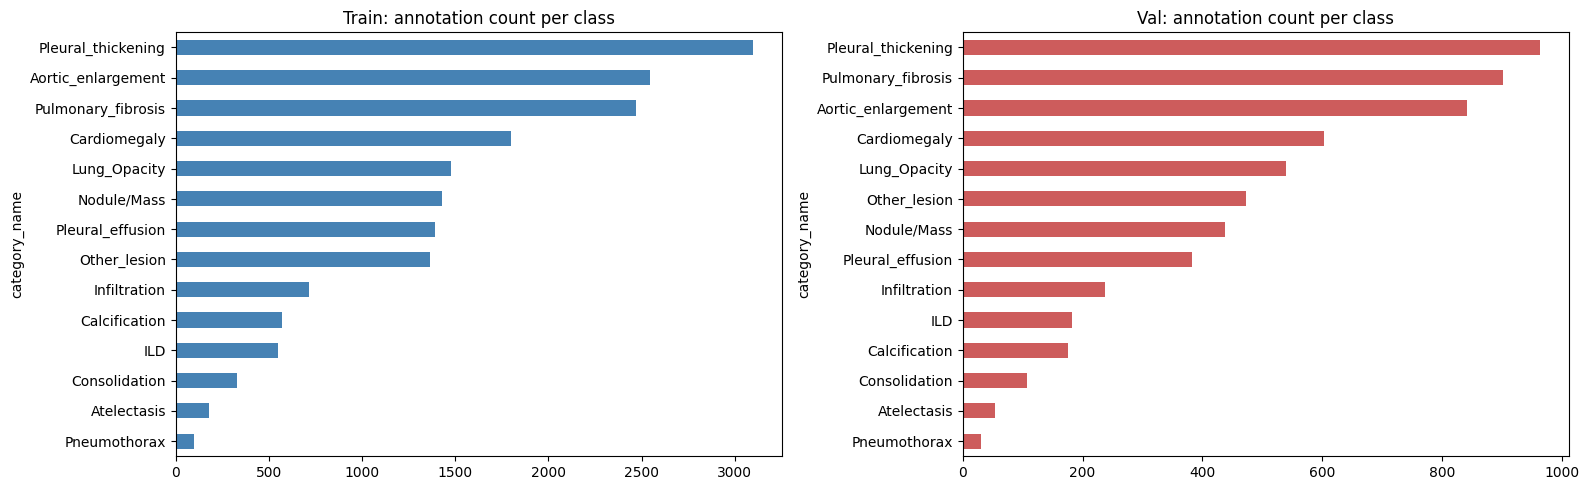

category_name
Pleural_thickening    3099
Aortic_enlargement    2545
Pulmonary_fibrosis    2472
Cardiomegaly          1800
Lung_Opacity          1479
Nodule/Mass           1431
Pleural_effusion      1391
Other_lesion          1364
Infiltration           718
Calcification          570
ILD                    550
Consolidation          328
Atelectasis            177
Pneumothorax           100
Name: count, dtype: int64


In [9]:

train_counts = train_df["category_name"].value_counts()
val_counts   = val_df["category_name"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
train_counts.sort_values().plot(kind="barh", ax=axes[0], color="steelblue")
axes[0].set_title("Train: annotation count per class")
val_counts.sort_values().plot(kind="barh", ax=axes[1], color="indianred")
axes[1].set_title("Val: annotation count per class")
plt.tight_layout(); plt.show()

print(train_counts)

count    3296.000000
mean        5.468447
std         4.254310
min         1.000000
25%         3.000000
50%         4.000000
75%         7.000000
max        42.000000
dtype: float64


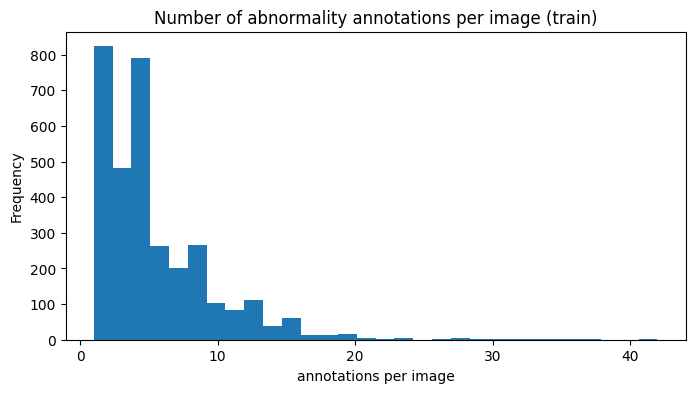

Images with >1 distinct abnormality class: 3047


In [10]:
# Images per class, and how many abnormalities per image (multi-label nature)
anns_per_image = train_df.groupby("file_name").size()
print(anns_per_image.describe())

plt.figure(figsize=(8,4))
anns_per_image.plot(kind="hist", bins=30)
plt.title("Number of abnormality annotations per image (train)")
plt.xlabel("annotations per image")
plt.show()

# Class co-occurrence per image
classes_per_image = train_df.groupby("file_name")["category_name"].apply(lambda s: set(s))
n_unique_classes = classes_per_image.apply(len)
print("Images with >1 distinct abnormality class:", (n_unique_classes > 1).sum())

# Bounding Box Analysis

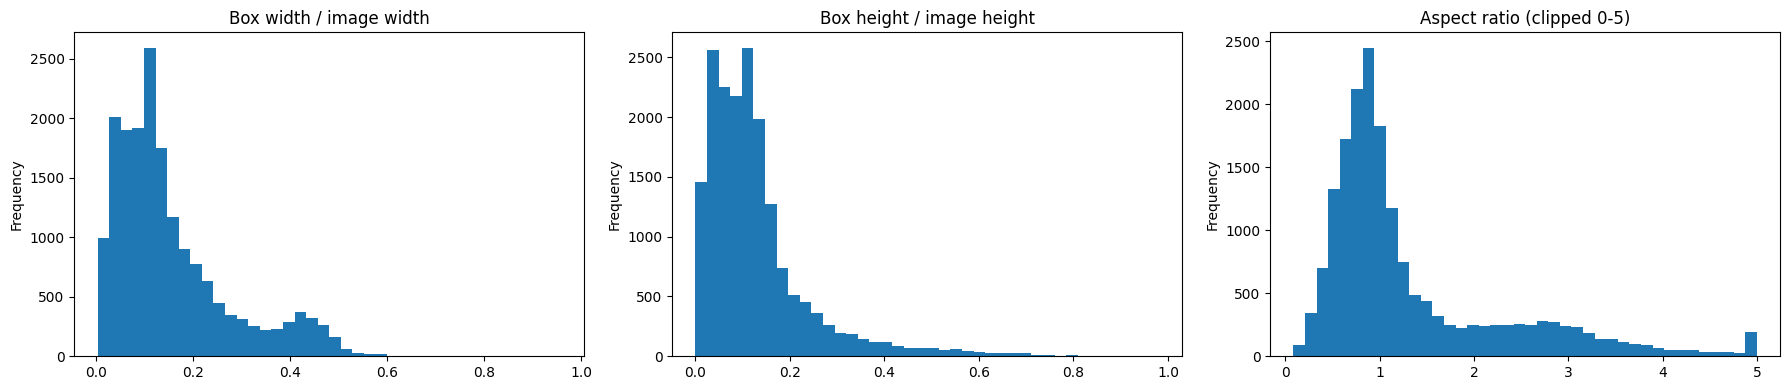

<Figure size 1200x600 with 0 Axes>

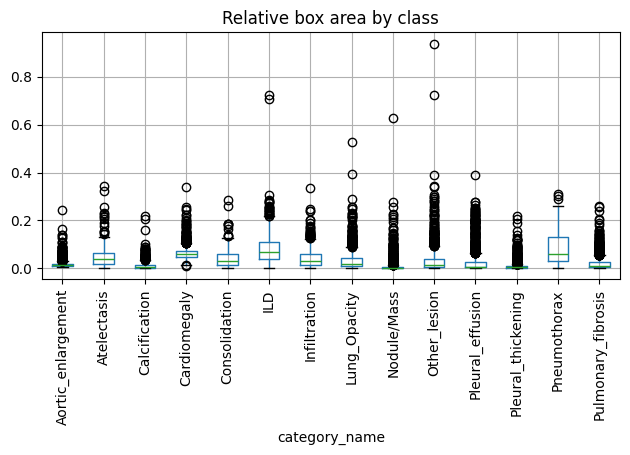

       img_width  img_height
0           1023        1004
3            846         985
6            846        1024
8            682         833
15           768         960
...          ...         ...
17974        674         818
17991        871         997
17994        735         757
18007        987        1014
18022        693         805

[1525 rows x 2 columns]


In [11]:
# Normalized box sizes (relative to image dims), and aspect ratios
train_df["w_norm"] = train_df["width"] / train_df["img_width"]
train_df["h_norm"] = train_df["height"] / train_df["img_height"]
train_df["aspect_ratio"] = train_df["width"] / train_df["height"]
train_df["rel_area"] = train_df["w_norm"] * train_df["h_norm"]

fig, axes = plt.subplots(1, 3, figsize=(18,4))
train_df["w_norm"].plot(kind="hist", bins=40, ax=axes[0], title="Box width / image width")
train_df["h_norm"].plot(kind="hist", bins=40, ax=axes[1], title="Box height / image height")
train_df["aspect_ratio"].clip(0,5).plot(kind="hist", bins=40, ax=axes[2], title="Aspect ratio (clipped 0-5)")
plt.tight_layout(); plt.show()

# Box size distribution per class
plt.figure(figsize=(12,6))
train_df.boxplot(column="rel_area", by="category_name", rot=90)
plt.title("Relative box area by class"); plt.suptitle("")
plt.tight_layout(); plt.show()

# Image dimension check — verify assumption that all images share one size
print(train_df[["img_width","img_height"]].drop_duplicates())

# Annotation Validation

In [12]:
issues = []

# Invalid box coords: negative, zero-area, or out-of-bounds
bad_wh = train_df[(train_df["width"] <= 0) | (train_df["height"] <= 0)]
issues.append(("zero/negative width or height", len(bad_wh)))

oob = train_df[
    (train_df["x_min"] < 0) | (train_df["y_min"] < 0) |
    (train_df["x_max"] > train_df["img_width"]) |
    (train_df["y_max"] > train_df["img_height"])
]
issues.append(("out-of-bounds boxes", len(oob)))

dup_anns = train_df.duplicated(subset=["file_name","category_id","x_min","y_min","width","height"]).sum()
issues.append(("exact duplicate annotations", dup_anns))

for name, count in issues:
    print(f"{name}: {count}")

if len(oob) > 0:
    print(oob[["file_name","x_min","y_min","x_max","y_max","img_width","img_height"]].head())

# Images with zero annotations (shouldn't exist per dataset note, but verify)
all_img_ids = set(img["id"] for img in train_coco["images"])
annotated_img_ids = set(train_df["image_id"])
no_ann_images = all_img_ids - annotated_img_ids
print(f"\nImages with zero annotations: {len(no_ann_images)}")

zero/negative width or height: 0
out-of-bounds boxes: 0
exact duplicate annotations: 0

Images with zero annotations: 0


# Image and Annotation Visualization

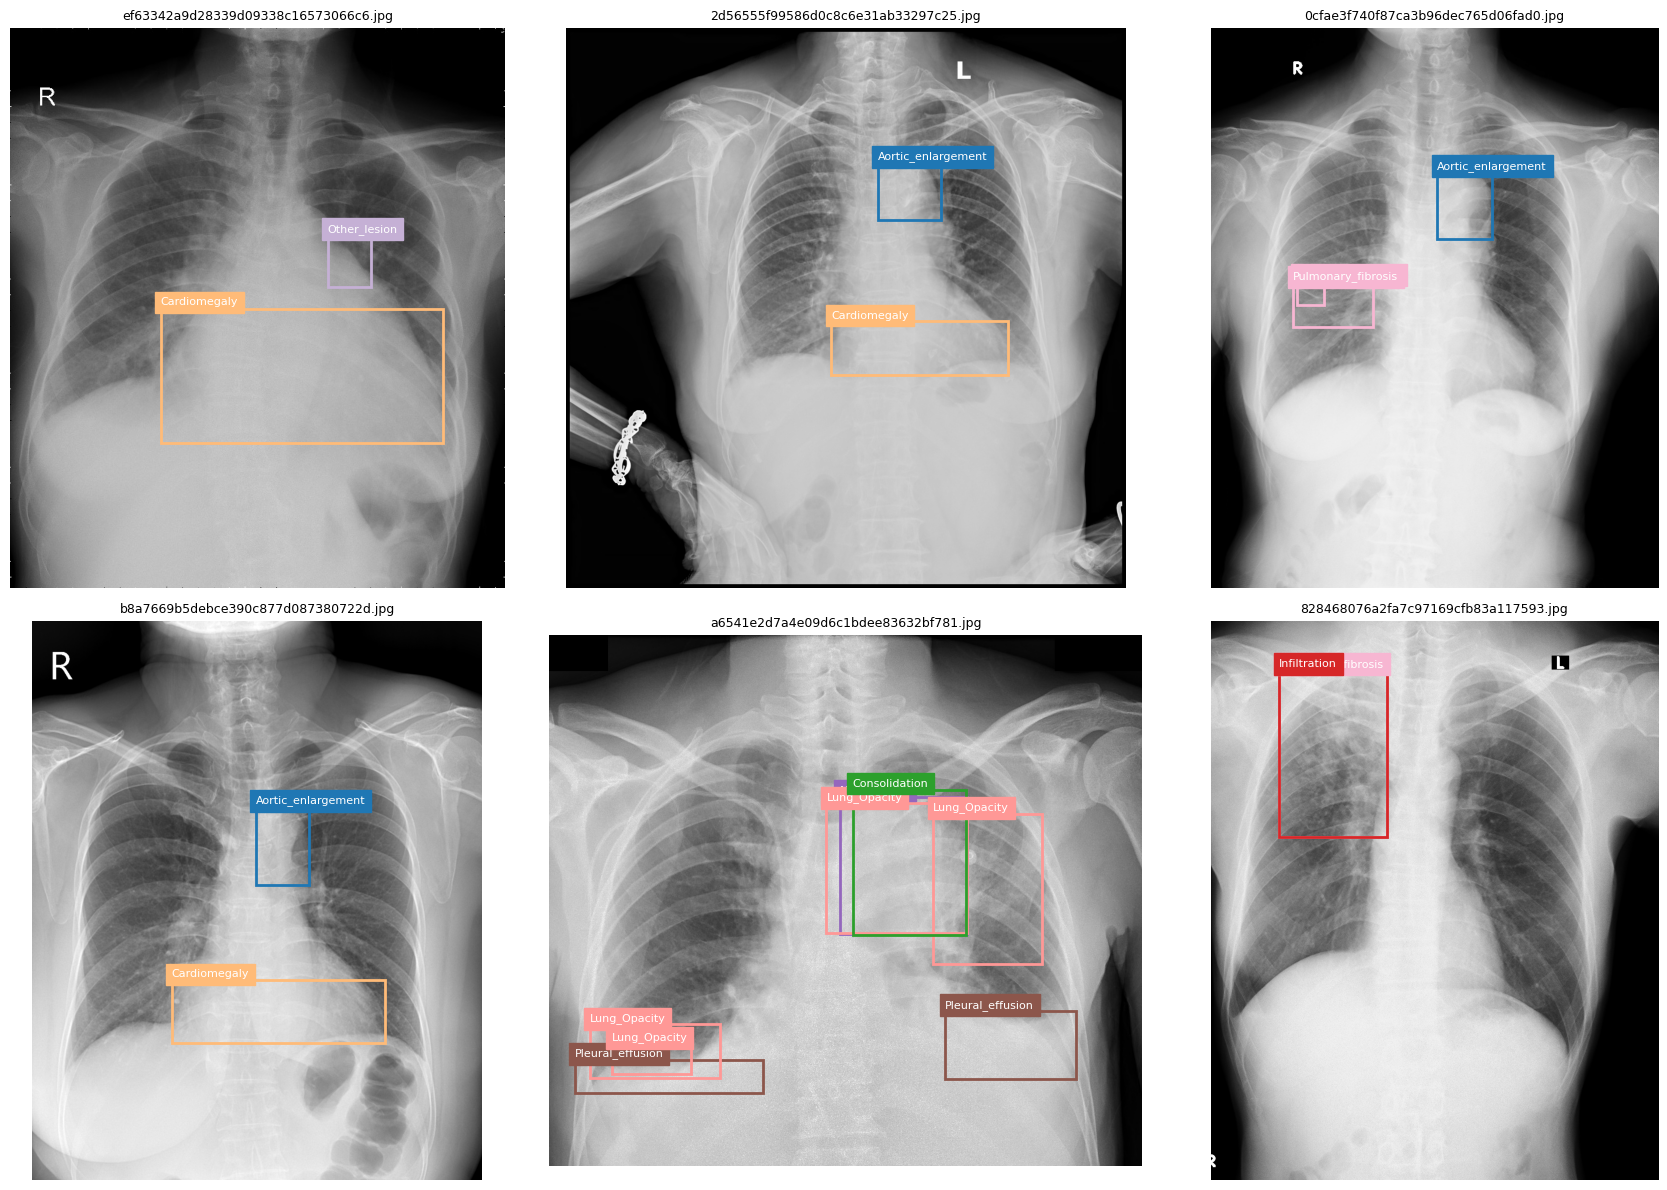

In [13]:
def draw_boxes(file_name, df, img_dir, ax=None):
    img_path = img_dir / file_name
    img = Image.open(img_path).convert("RGB")
    if ax is None:
        fig, ax = plt.subplots(1, figsize=(8,8))
    ax.imshow(img)
    rows = df[df["file_name"] == file_name]
    colors = plt.cm.tab20.colors
    for _, r in rows.iterrows():
        color = colors[int(r["category_id"]) % 20]
        rect = patches.Rectangle((r["x_min"], r["y_min"]), r["width"], r["height"],
                                  linewidth=2, edgecolor=color, facecolor="none")
        ax.add_patch(rect)
        ax.text(r["x_min"], max(r["y_min"]-5,0), r["category_name"],
                 color="white", fontsize=8, backgroundcolor=color)
    ax.set_title(file_name, fontsize=9)
    ax.axis("off")

sample_files = random.sample(list(train_df["file_name"].unique()), 6)
fig, axes = plt.subplots(2, 3, figsize=(18,12))
for ax, fname in zip(axes.flatten(), sample_files):
    draw_boxes(fname, train_df, train_img_dir, ax=ax)
plt.tight_layout(); plt.show()

# COCO to YOLO Conversion

In [14]:
YOLO_ROOT = Path("/kaggle/working/yolo_dataset")
for split in ["train", "val"]:
    (YOLO_ROOT / "images" / split).mkdir(parents=True, exist_ok=True)
    (YOLO_ROOT / "labels" / split).mkdir(parents=True, exist_ok=True)

# Build a stable, sorted class-id mapping: COCO category_id -> YOLO index (0..N-1)
sorted_cats = sorted(categories, key=lambda c: c["id"])
coco_id_to_yolo_idx = {c["id"]: i for i, c in enumerate(sorted_cats)}
yolo_idx_to_name = {i: c["name"] for i, c in enumerate(sorted_cats)}
print(coco_id_to_yolo_idx)
print(yolo_idx_to_name)

def convert_split(coco_json, img_dir, split_name):
    img_info = {img["id"]: img for img in coco_json["images"]}
    anns_by_image = defaultdict(list)
    for ann in coco_json["annotations"]:
        anns_by_image[ann["image_id"]].append(ann)

    n_written, n_skipped = 0, 0
    for img_id, img in img_info.items():
        fname = img["file_name"]
        src = img_dir / fname
        if not src.exists():
            n_skipped += 1
            continue

        dst_img = YOLO_ROOT / "images" / split_name / fname
        if not dst_img.exists():
            os.symlink(src.resolve(), dst_img)  # symlink saves disk/time; use shutil.copy if symlink unsupported

        lbl_path = YOLO_ROOT / "labels" / split_name / (Path(fname).stem + ".txt")
        lines = []
        W, H = img["width"], img["height"]
        for ann in anns_by_image.get(img_id, []):
            x, y, w, h = ann["bbox"]
            cx = (x + w/2) / W
            cy = (y + h/2) / H
            nw = w / W
            nh = h / H
            # clip to [0,1] defensively
            cx, cy, nw, nh = [min(max(v,0.0),1.0) for v in (cx,cy,nw,nh)]
            yolo_cls = coco_id_to_yolo_idx[ann["category_id"]]
            lines.append(f"{yolo_cls} {cx:.6f} {cy:.6f} {nw:.6f} {nh:.6f}")

        with open(lbl_path, "w") as f:
            f.write("\n".join(lines))
        n_written += 1

    print(f"{split_name}: wrote {n_written} label files, skipped {n_skipped} missing images")

convert_split(train_coco, train_img_dir, "train")
convert_split(val_coco, val_img_dir, "val")

{0: 0, 1: 1, 2: 2, 3: 3, 4: 4, 5: 5, 6: 6, 7: 7, 8: 8, 9: 9, 10: 10, 11: 11, 12: 12, 13: 13}
{0: 'Aortic_enlargement', 1: 'Atelectasis', 2: 'Calcification', 3: 'Cardiomegaly', 4: 'Consolidation', 5: 'ILD', 6: 'Infiltration', 7: 'Lung_Opacity', 8: 'Nodule/Mass', 9: 'Other_lesion', 10: 'Pleural_effusion', 11: 'Pleural_thickening', 12: 'Pneumothorax', 13: 'Pulmonary_fibrosis'}
train: wrote 3296 label files, skipped 0 missing images
val: wrote 1098 label files, skipped 0 missing images


# YOLO Dataset Validation

train: 3296 images, 3296 label files
  empty label files: 0
  invalid lines in sampled files: 0
val: 1098 images, 1098 label files
  empty label files: 0
  invalid lines in sampled files: 0


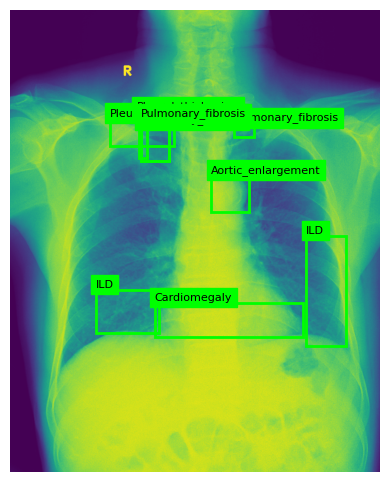

In [15]:
def validate_yolo_split(split_name):
    img_files = list((YOLO_ROOT/"images"/split_name).glob("*.jpg"))
    lbl_files = list((YOLO_ROOT/"labels"/split_name).glob("*.txt"))
    print(f"{split_name}: {len(img_files)} images, {len(lbl_files)} label files")

    empty_labels = sum(1 for f in lbl_files if f.stat().st_size == 0)
    print(f"  empty label files: {empty_labels}")

    # Spot-check a few label files for valid class indices and normalized coords
    bad = 0
    for f in random.sample(lbl_files, min(50, len(lbl_files))):
        for line in f.read_text().splitlines():
            if not line.strip():
                continue
            parts = line.split()
            cls = int(parts[0])
            coords = list(map(float, parts[1:]))
            if not (0 <= cls < NUM_CLASSES) or not all(0 <= c <= 1 for c in coords):
                bad += 1
    print(f"  invalid lines in sampled files: {bad}")

validate_yolo_split("train")
validate_yolo_split("val")

# Visualize a converted YOLO sample to confirm correctness
def show_yolo_sample(split_name, idx=0):
    img_files = sorted((YOLO_ROOT/"images"/split_name).glob("*.jpg"))
    img_path = img_files[idx]
    lbl_path = YOLO_ROOT/"labels"/split_name/(img_path.stem + ".txt")
    img = Image.open(img_path)
    W, H = img.size
    fig, ax = plt.subplots(figsize=(6,6))
    ax.imshow(img)
    for line in lbl_path.read_text().splitlines():
        cls, cx, cy, w, h = map(float, line.split())
        cls = int(cls)
        x_min = (cx - w/2) * W
        y_min = (cy - h/2) * H
        rect = patches.Rectangle((x_min,y_min), w*W, h*H, linewidth=2, edgecolor="lime", facecolor="none")
        ax.add_patch(rect)
        ax.text(x_min, y_min-5, yolo_idx_to_name[cls], color="black", backgroundcolor="lime", fontsize=8)
    ax.axis("off"); plt.show()

show_yolo_sample("train", 0)

# data.yaml Creation

In [16]:
yaml_content = f"""path: {YOLO_ROOT}
train: images/train
val: images/val

nc: {NUM_CLASSES}
names: {[yolo_idx_to_name[i] for i in range(NUM_CLASSES)]}
"""
data_yaml_path = YOLO_ROOT / "data.yaml"
with open(data_yaml_path, "w") as f:
    f.write(yaml_content)
print(yaml_content)

path: /kaggle/working/yolo_dataset
train: images/train
val: images/val

nc: 14
names: ['Aortic_enlargement', 'Atelectasis', 'Calcification', 'Cardiomegaly', 'Consolidation', 'ILD', 'Infiltration', 'Lung_Opacity', 'Nodule/Mass', 'Other_lesion', 'Pleural_effusion', 'Pleural_thickening', 'Pneumothorax', 'Pulmonary_fibrosis']



# Baseline YOLO Model and Transfer Learning

In [17]:
# Baseline: pretrained COCO weights, small model for speed, transfer-learned onto our classes
model = YOLO("yolov8s.pt")   # pretrained backbone -> transfer learning

# Model Training

In [18]:
results = model.train(
    data=str(data_yaml_path),
    epochs=60,
    imgsz=640,
    batch=16,
    device=DEVICE,
    patience=15,
    optimizer="auto",
    seed=SEED,
    project="/kaggle/working/runs",
    name="vinbigdata_yolov8s",
    val=True,
    plots=True,
)

Ultralytics 8.4.123 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=60, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=vinbigdata_yolov8s, nb

# Validation and Evaluation

In [19]:
best_weights = "/kaggle/working/runs/vinbigdata_yolov8s/weights/best.pt"
model_best = YOLO(best_weights)

metrics = model_best.val(data=str(data_yaml_path), split="val", device=DEVICE)
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)
print("Per-class mAP50:", dict(zip([yolo_idx_to_name[i] for i in range(NUM_CLASSES)], metrics.box.ap50)))

Ultralytics 8.4.123 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 11,131,002 parameters, 0 gradients, 28.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 202.4±112.3 MB/s, size: 196.4 KB)
val: Scanning /kaggle/working/yolo_dataset/labels/val.cache... 1098 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1098/1098 418.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 69/69 4.9it/s 14.1s0.2s
                   all       1098       5931      0.438      0.414      0.374      0.187
    Aortic_enlargement        760        842      0.785       0.86      0.884      0.552
           Atelectasis         45         53       0.31      0.255      0.263      0.101
         Calcification        108        175      0.324      0.214      0.168     0.0684
          Cardiomegaly        577        603       0.84      0.886      0.904      0.623
         Consolidation     

# Prediction Visualization


0: 640x640 1 Aortic_enlargement, 1 Cardiomegaly, 12.7ms
1: 640x640 1 Aortic_enlargement, 1 Cardiomegaly, 12.7ms
2: 640x640 1 Aortic_enlargement, 12.7ms
3: 640x640 1 Aortic_enlargement, 1 Cardiomegaly, 1 Lung_Opacity, 1 Other_lesion, 12.7ms
4: 640x640 1 Atelectasis, 1 Pleural_effusion, 1 Pleural_thickening, 12.7ms
5: 640x640 1 Aortic_enlargement, 12.7ms
Speed: 2.7ms preprocess, 12.7ms inference, 0.9ms postprocess per image at shape (1, 3, 640, 640)


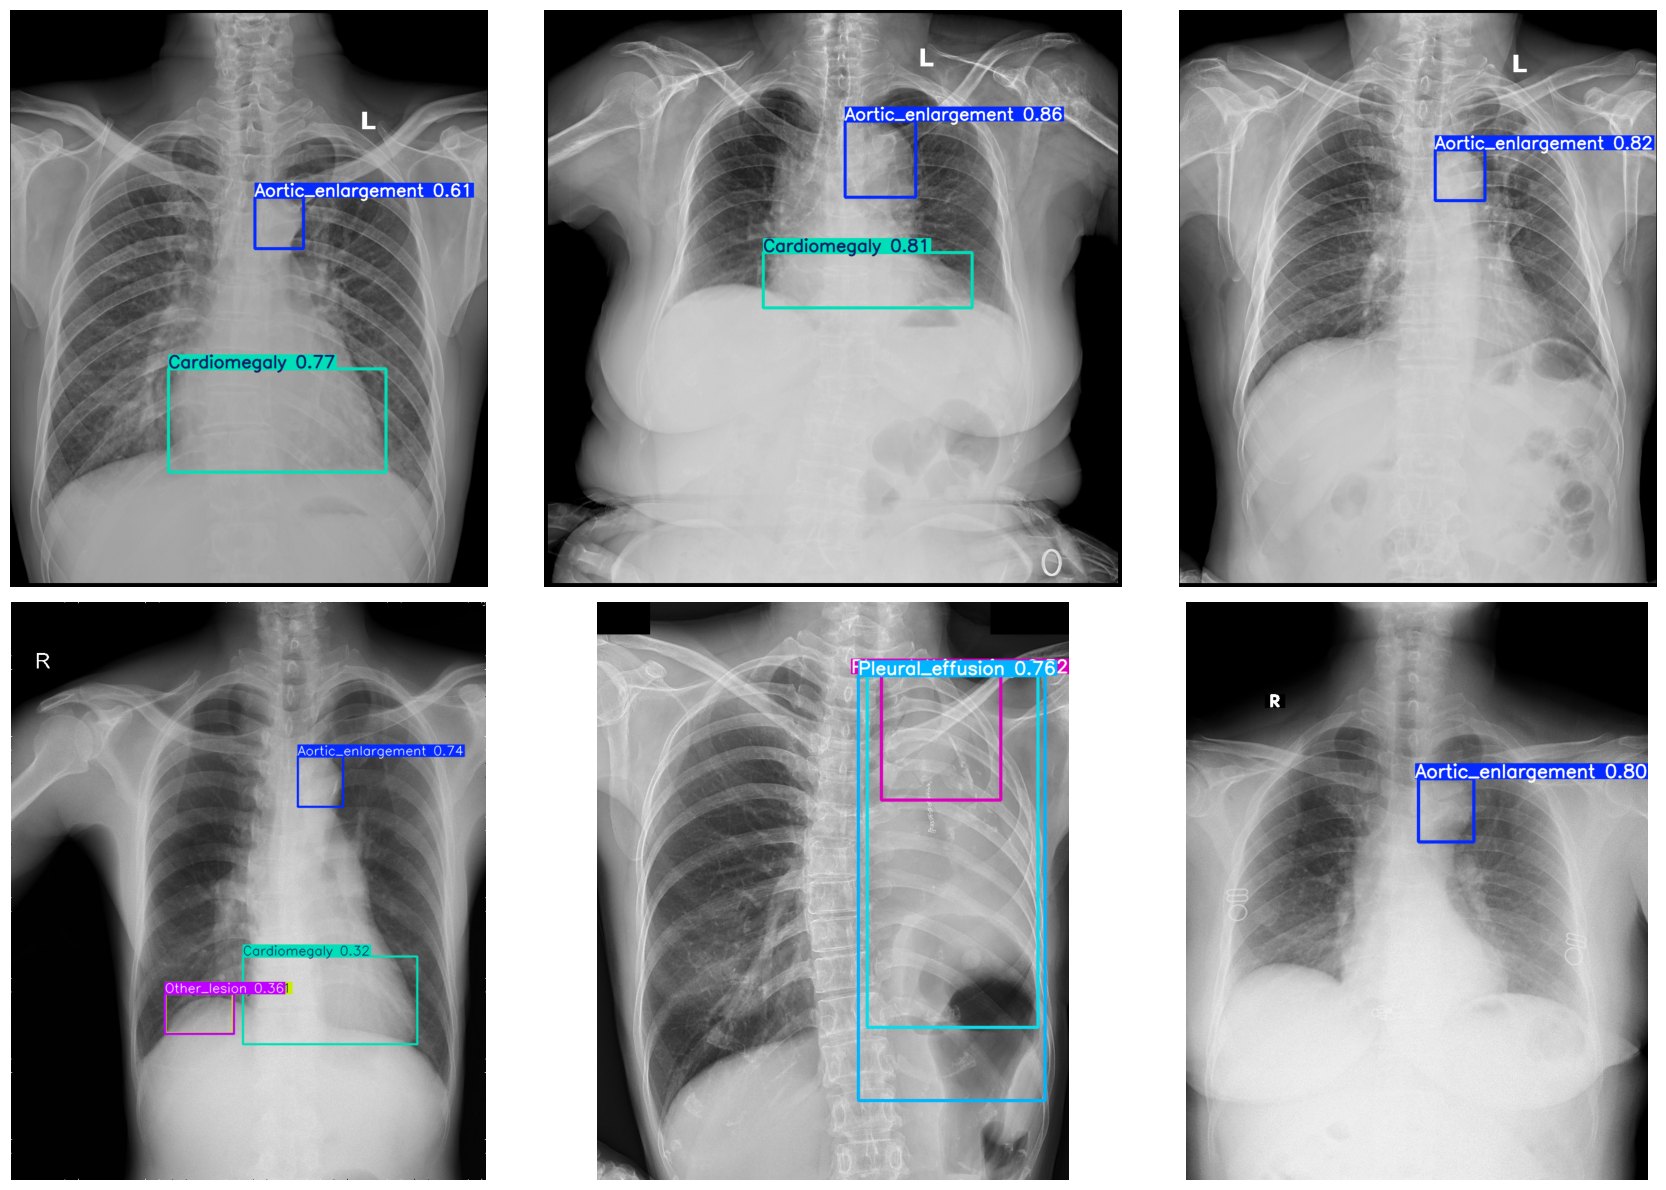

In [20]:
val_imgs = list((YOLO_ROOT/"images"/"val").glob("*.jpg"))
sample_preds = random.sample(val_imgs, 6)

preds = model_best.predict(sample_preds, conf=0.25, device=DEVICE)
fig, axes = plt.subplots(2, 3, figsize=(18,12))
for ax, r in zip(axes.flatten(), preds):
    im = r.plot()  # numpy array with boxes drawn
    ax.imshow(im[..., ::-1])  # BGR->RGB
    ax.axis("off")
plt.tight_layout(); plt.show()

# Error Analysis

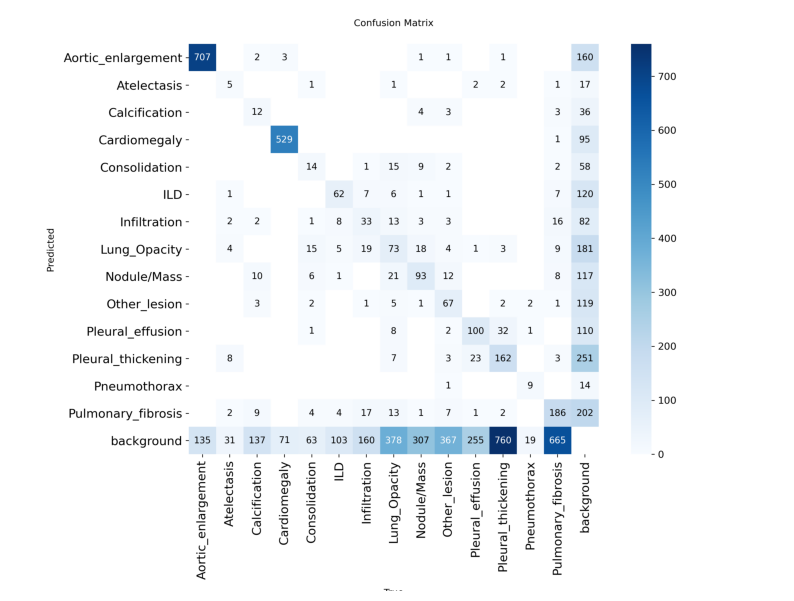


0: 640x640 1 Aortic_enlargement, 1 Cardiomegaly, 1 Lung_Opacity, 1 Pleural_thickening, 2 Pulmonary_fibrosiss, 12.8ms
1: 640x640 1 Aortic_enlargement, 1 Cardiomegaly, 2 Pleural_thickenings, 12.8ms
2: 640x640 1 Aortic_enlargement, 1 Infiltration, 1 Lung_Opacity, 4 Pleural_thickenings, 3 Pulmonary_fibrosiss, 12.8ms
3: 640x640 1 Aortic_enlargement, 1 Cardiomegaly, 1 Lung_Opacity, 1 Other_lesion, 1 Pleural_thickening, 12.8ms
4: 640x640 1 Atelectasis, 1 Lung_Opacity, 1 Pleural_effusion, 1 Pleural_thickening, 12.8ms
5: 640x640 1 Aortic_enlargement, 12.8ms
Speed: 2.5ms preprocess, 12.8ms inference, 0.8ms postprocess per image at shape (1, 3, 640, 640)


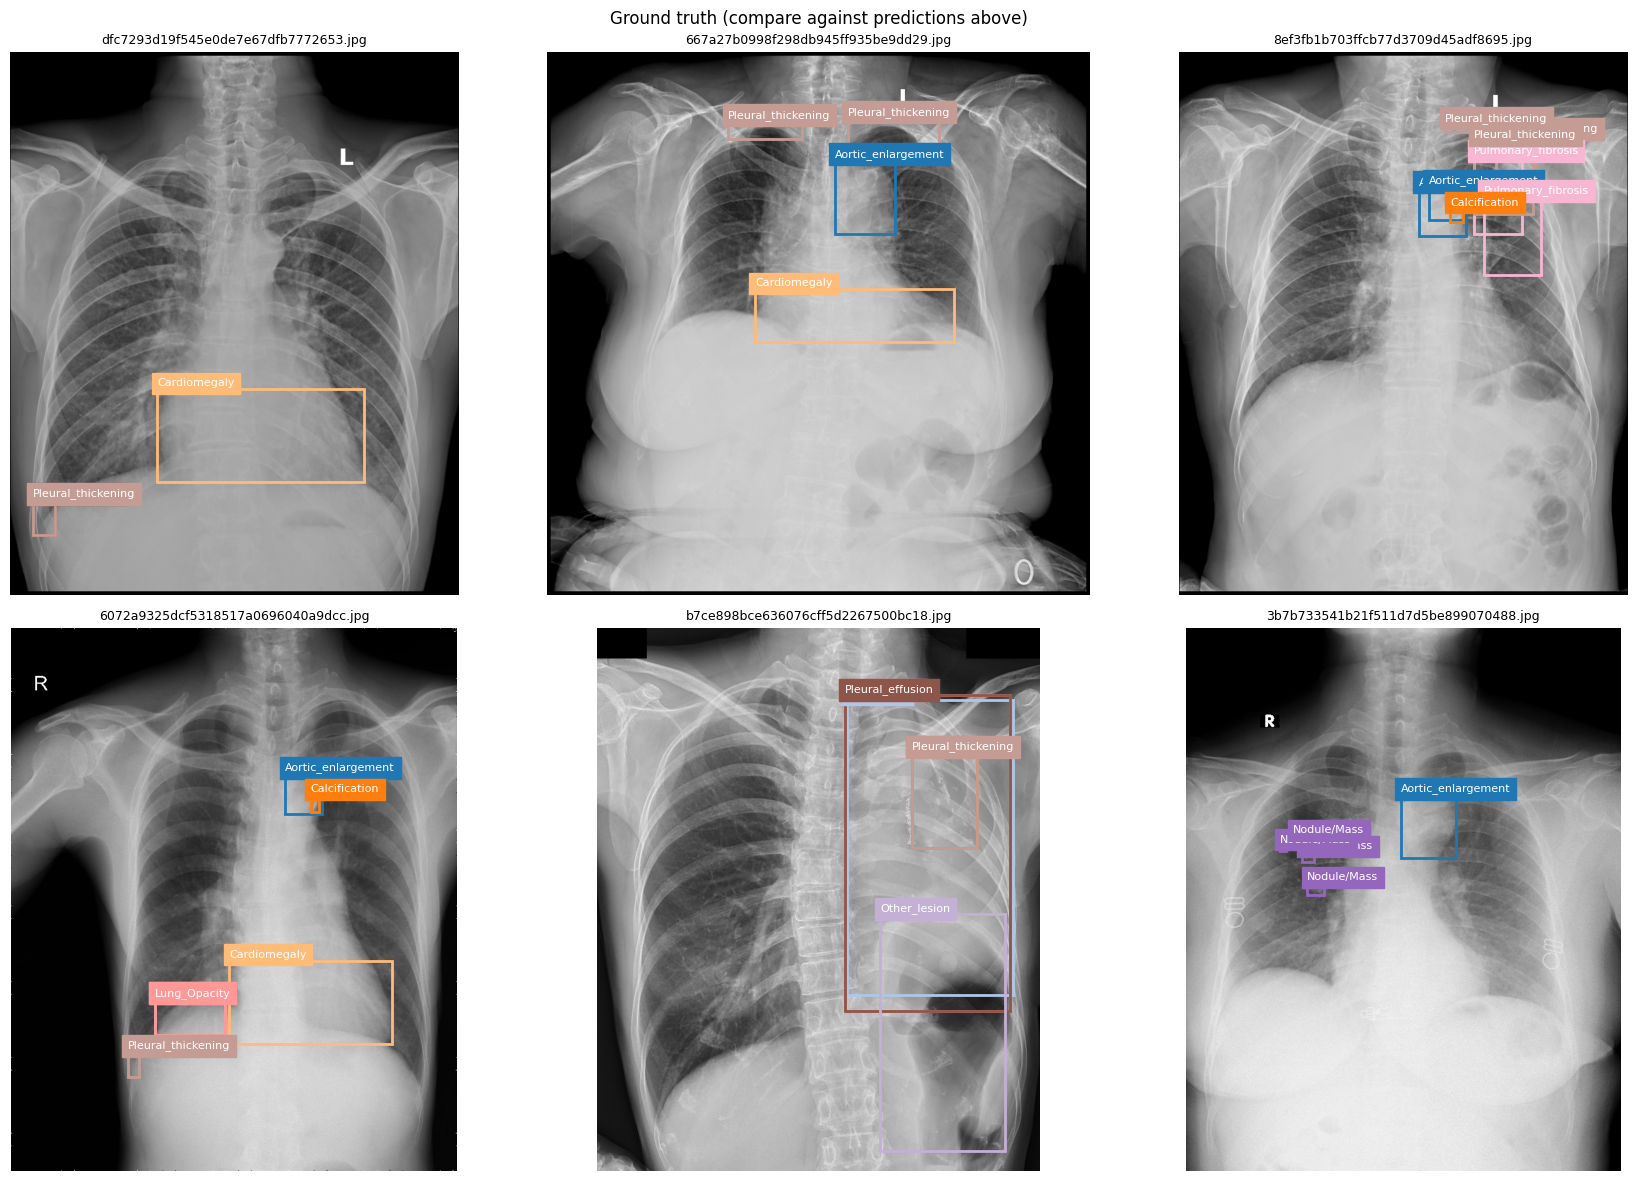

In [21]:


import cv2
conf_matrix_path = "/kaggle/working/runs/vinbigdata_yolov8s/confusion_matrix.png"
if os.path.exists(conf_matrix_path):
    img = plt.imread(conf_matrix_path)
    plt.figure(figsize=(10,10)); plt.imshow(img); plt.axis("off"); plt.show()

# Manually inspect false positives/negatives on a few val images at low confidence
low_conf_preds = model_best.predict(sample_preds, conf=0.1, device=DEVICE)
# Compare predicted boxes vs ground-truth boxes side by side
fig, axes = plt.subplots(2, 3, figsize=(18,12))
for ax, fname in zip(axes.flatten(), [p.stem+".jpg" for p in sample_preds]):
    draw_boxes(fname, val_df, val_img_dir, ax=ax)  # ground truth
plt.suptitle("Ground truth (compare against predictions above)")
plt.tight_layout(); plt.show()

In [22]:
from ultralytics import YOLO

best_weights = "/kaggle/working/runs/vinbigdata_yolov8s/weights/best.pt"
model_best = YOLO(best_weights)

In [23]:
metrics = model_best.val(
    data=str(data_yaml_path),
    split="val",
    device=DEVICE,
    conf=0.25,     # confidence threshold for counting a prediction
    iou=0.5,       # IoU threshold for matching a prediction to ground truth
    plots=True,
)

print("mAP50:      ", metrics.box.map50)      # overall accuracy at IoU=0.5
print("mAP50-95:   ", metrics.box.map)        # stricter, averaged over IoU 0.5-0.95
print("Mean Precision:", metrics.box.mp)
print("Mean Recall:   ", metrics.box.mr)

Ultralytics 8.4.123 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 11,131,002 parameters, 0 gradients, 28.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 293.9±94.1 MB/s, size: 186.9 KB)
val: Scanning /kaggle/working/yolo_dataset/labels/val.cache... 1098 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1098/1098 418.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 69/69 5.0it/s 13.9s0.2s
                   all       1098       5931      0.542      0.362      0.285      0.151
    Aortic_enlargement        760        842       0.81      0.836        0.8      0.504
           Atelectasis         45         53       0.48      0.226      0.162      0.061
         Calcification        108        175      0.407      0.126     0.0753     0.0327
          Cardiomegaly        577        603      0.852      0.876      0.848      0.586
         Consolidation      

In [24]:
class_names = [yolo_idx_to_name[i] for i in range(NUM_CLASSES)]

per_class_df = pd.DataFrame({
    "class": class_names,
    "precision": metrics.box.p,
    "recall": metrics.box.r,
    "mAP50": metrics.box.ap50,
    "mAP50-95": metrics.box.ap,
})
per_class_df = per_class_df.sort_values("mAP50", ascending=False)
per_class_df

,class,precision,recall,mAP50,mAP50-95
3,Cardiomegaly,0.851613,0.875622,0.848044,0.586450
0,Aortic_enlargement,0.810127,0.836105,0.800264,0.503960
5,ILD,0.428571,0.426230,0.300475,0.153392
10,Pleural_effusion,0.577273,0.332461,0.275741,0.109692
8,Nodule/Mass,0.555556,0.319635,0.248128,0.130560
4,Consolidation,0.453488,0.364486,0.240420,0.091979
6,Infiltration,0.520548,0.319328,0.233125,0.106996
13,Pulmonary_fibrosis,0.609499,0.256098,0.206735,0.071975
7,Lung_Opacity,0.495050,0.277778,0.190828,0.078889
12,Pneumothorax,0.478261,0.354839,0.184174,0.107509


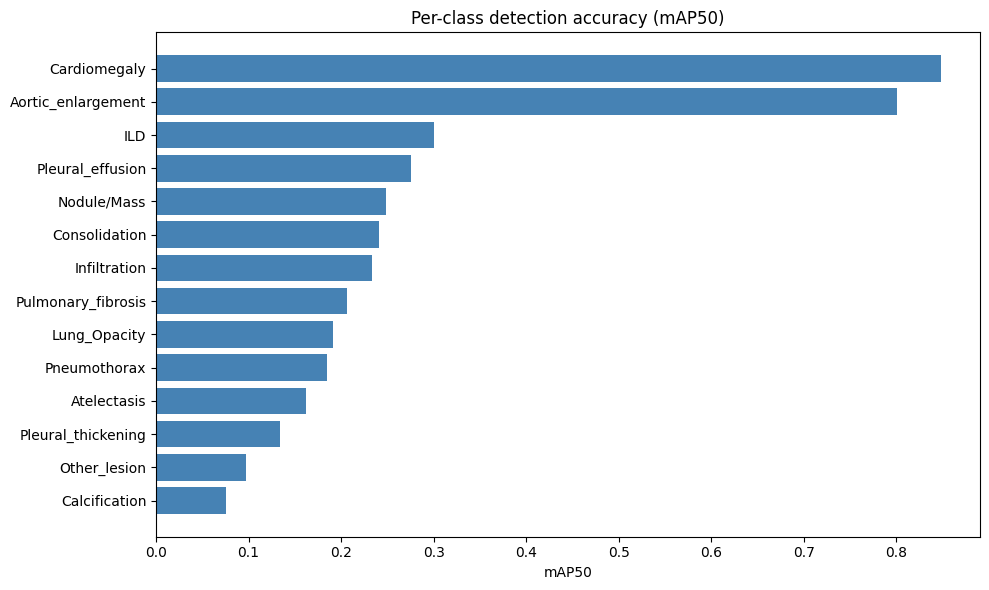

In [25]:
plt.figure(figsize=(10,6))
plt.barh(per_class_df["class"], per_class_df["mAP50"], color="steelblue")
plt.xlabel("mAP50"); plt.title("Per-class detection accuracy (mAP50)")
plt.gca().invert_yaxis()
plt.tight_layout(); plt.show()

In [26]:
best_weights = "/kaggle/working/runs/vinbigdata_yolov8s/weights/best.pt"

# Copy to a clean deployment folder
import shutil, os
os.makedirs("/kaggle/working/deploy", exist_ok=True)
shutil.copy(best_weights, "/kaggle/working/deploy/best.pt")

# Also save the class names so the app doesn't depend on the notebook's variables
import json
with open("/kaggle/working/deploy/classes.json", "w") as f:
    json.dump(yolo_idx_to_name, f)

print("Deployment files ready in /kaggle/working/deploy/")

Deployment files ready in /kaggle/working/deploy/


In [27]:
shutil.make_archive("/kaggle/working/vinbigdata_deploy", "zip", "/kaggle/working/deploy")

'/kaggle/working/vinbigdata_deploy.zip'

# Conclusion


### Key Results
The final YOLOv8s model (evaluated at conf=0.25, IoU=0.5) achieved:
- mAP50: 0.285, mAP50-95: 0.151
- Mean precision: 0.542, mean recall: 0.362

Performance was uneven across classes. The model did well on **Cardiomegaly**
(mAP50 0.85) and **Aortic_enlargement** (mAP50 0.80) — both are large, anatomically
well-defined findings with clear, consistent box shapes. It performed poorly on
**Calcification** (mAP50 0.075), **Other_lesion** (0.097), and **Pleural_thickening**
(0.133) — despite Pleural_thickening being the single most frequent class in
training (3,099 annotations). This suggests raw annotation count isn't the only
driver of difficulty: diffuse, subtle, or inconsistently-bounded findings are
harder to localize than compact, high-contrast ones, regardless of how much
training data exists for them. Rare classes with few examples (Pneumothorax: 100,
Atelectasis: 177) also underperformed, consistent with data scarcity.

### Limitations
- Only one model configuration was trained (YOLOv8s, default augmentation,
  60 epochs); no hyperparameter search or model-size comparison was performed.
- No class-imbalance mitigation (e.g. class weighting, oversampling, focal loss)
  was applied, despite a >30x gap between the most and least frequent classes.
- Evaluation used the provided validation split only; no held-out test set was
  available to confirm the metrics generalize beyond this split.
- Multi-label co-occurrence (most images have >1 abnormality) was noted in EDA
  but not specifically addressed in training or evaluation.

### Future Work
- Apply class-weighted loss or oversampling for rare/poorly-performing classes.
- Try larger YOLO variants (e.g. YOLOv8m/l) or longer training with tuned
  augmentation to see if the weaker classes improve.
- Run a small hyperparameter sweep (learning rate, image size, augmentation
  strength) rather than relying on defaults.
- Add Grad-CAM or similar visual explanations for low-confidence predictions to
  better understand failure modes on diffuse-pattern classes.